# What price should Dish Up charge per box?

**Question:** Which price earns the most revenue, based on what students said they would pay?

**Data:** `dish_up_surveys_clean.csv`, 280 cleaned survey responses (output of `01_cleaning.ipynb`).

**Method:** For each price from €4 to €10, I counted the share of students willing to pay that price or more.
Then I multiplied price × share × 100 to get revenue per 100 students.

**Finding:** Revenue per 100 students is highest at **€5 (€468)**. At €6 it drops to €403,
and above €7 it falls quickly, because most students said €5–6.

**Caveats:**
1. **Not a random sample.** Most replies came from one university (about 65% Tallinn University),
   so other students may be willing to pay different amounts.
2. **Stated, not real, behaviour.** This is what students *said* they would pay in a survey.
   People often act differently when real money is involved.
3. **Revenue is not profit.** I don't include the café's share or the cost of each box,
   so the most profitable price could be different.



In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Load the data

In [2]:
clean = pd.read_csv("dish_up_surveys_clean.csv")
print(clean.shape)
clean.head()

(280, 8)


,response_id,submitted_at,school,home_area_raw,price_eur,launch_opt_in,school_group,district
0,R001,2026-09-29 10:28:00,Estonian Academy of Arts,Kalamaja,5,0,Other,Põhja-Tallinn
1,R002,2026-09-09 14:34:00,Tallinn University,Kesklinn,6,1,Tallinn University,Kesklinn
2,R003,2026-09-07 16:13:00,Tallinn University,Kesklinn,6,1,Tallinn University,Kesklinn
3,R004,2026-09-03 18:51:00,Tallinn University,Pirita,5,1,Tallinn University,Pirita
4,R005,2026-09-03 18:33:00,Tallinn University,Aespa,5,1,Tallinn University,Other


## 2. What prices did students say?
Each student picked the most they would pay for one box.

In [3]:
price_counts = clean["price_eur"].value_counts().sort_index()
price_counts

price_eur
4     18
5     74
6     99
7     44
8     33
9      3
10     9
Name: count, dtype: int64

In [4]:
print("Average:", round(clean["price_eur"].mean(), 2))
print("Median:", clean["price_eur"].median())

Average: 6.16
Median: 6.0


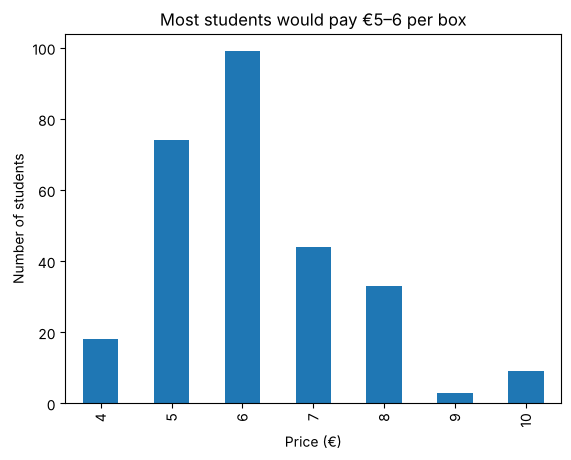

In [5]:
price_counts.plot(kind="bar")
plt.xlabel("Price (€)")
plt.ylabel("Number of students")
plt.title("Most students would pay €5–6 per box")
plt.show()

Most answers are €5 or €6. The average (€6.16) and median (€6) are close, so a few high answers don't distort the picture.

## 3. Revenue at each price
If Dish Up charges a price, everyone who said that price **or more** would buy.
So for each price: share who would buy × price × 100 = revenue per 100 students.

In [6]:
prices = [4, 5, 6, 7, 8, 9, 10]
shares = []
revenues = []

for p in prices:
    share = (clean["price_eur"] >= p).mean()
    shares.append(share)
    revenues.append(p * share * 100)

results = pd.DataFrame({"price": prices, "share_who_buy": shares, "revenue_per_100": revenues})
results.round(2)

,price,share_who_buy,revenue_per_100
0,4,1.00,400.00
1,5,0.94,467.86
2,6,0.67,402.86
3,7,0.32,222.50
4,8,0.16,128.57
5,9,0.04,38.57
6,10,0.03,32.14


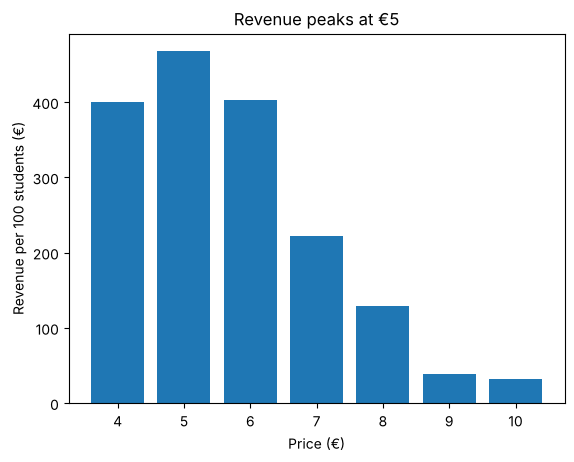

In [7]:
plt.bar(prices, revenues)
plt.xlabel("Price (€)")
plt.ylabel("Revenue per 100 students (€)")
plt.title("Revenue peaks at €5")
plt.show()

## 4. Result
- **€5 earns the most:** about €468 per 100 students.
- **€6 earns about €403.** Fewer students drop out than at higher prices, but enough to lose ~€65 per 100.
- **Above €7, revenue falls fast**, because very few students said €8 or more.

Because of the caveats at the top, this is a starting point, not a final price.
The next step is a real test: show half of new customers €5 and half €6, and compare revenue per visitor.